# R7-H1 - Experimento B1: entrenamiento sin early stopping

**Objetivo.** Evaluar si el early stopping utilizado en R4–R6 interrumpió el entrenamiento de ConvNeXt-Tiny con la imagen completa (representación A) antes de que el modelo terminara de aprender.

**Hipótesis (H1).** Completar 30 épocas, en lugar de detener el entrenamiento según `val_weighted_loss`, modifica el desempeño del checkpoint seleccionado por máximo `val_roc_auc`. No se presupone el sentido del cambio: podría haber mejora, ninguna diferencia o deterioro.

**Diseño.** Se comparan dos configuraciones con las mismas semillas (42, 43 y 44) y el mismo conjunto de validación:

| | B0 (basal) | B1 |
|---|---|---|
| Origen | Entrenamientos de R4, reutilizados en R6 (solo lectura) | Tres entrenamientos nuevos, ejecutados en Falcon |
| Early stopping | Activo (paciencia 5, `min_delta` 0.001) | Desactivado: 30 épocas |

Todo lo demás es idéntico en ambas configuraciones: arquitectura, representación A, particiones, hiperparámetros, pesos de clase, pérdida, data augmentation, checkpoint por máximo `val_roc_auc` y umbral 0.5.

## 1. Configuración

In [1]:
from pathlib import Path
import json
import shlex
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import average_precision_score, roc_auc_score


def locate_project_root() -> Path:
    current_dir = Path.cwd().resolve()

    for candidate in [current_dir, *current_dir.parents]:
        if (candidate / "src").exists() and (candidate / "data").exists():
            return candidate

    raise FileNotFoundError("No se pudo localizar la raíz del proyecto.")


PROJECT_ROOT = locate_project_root()

ARCH = "convnext_tiny"
CONDITION = "A"
SEEDS = [42, 43, 44]
EPOCHS_MAX = 30
THRESHOLD = 0.5
EXPERIMENT_NAME = "r7_early_stopping"  # etiqueta que run_experiment registra en el run_config de B1

CLASSIFICATION_DIR = PROJECT_ROOT / "results" / "classification"
B0_DIR = CLASSIFICATION_DIR / "r4_benchmark" / ARCH / CONDITION  # solo lectura
B1_DIR = CLASSIFICATION_DIR / "r7_optimizacion" / "early_stopping"
ANALYSIS_DIR = B1_DIR / "analysis"
SPLIT_MANIFEST = PROJECT_ROOT / "configs" / "splits" / "mmotu_experimental_split_standard.csv"

HISTORY_KEYS = [
    "train_loss", "train_acc", "val_loss", "val_unweighted_loss", "val_acc", "val_roc_auc",
    "val_average_precision", "val_f1_malignant", "val_recall_malignant", "val_specificity", "val_balanced_accuracy",
]
# Nombres reales en los archivos: `val_loss` es la pérdida ponderada de validation y la sensibilidad es `recall_malignant`
SAVED_KEYS = {"roc_auc": "roc_auc", "average_precision": "average_precision", "sensitivity": "recall_malignant", "specificity": "specificity"}

COLORS = {"B0": "#0072B2", "B1": "#D55E00"}
LABELS = {"B0": "B0 (con early stopping)", "B1": "B1 (30 épocas)"}

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})


def b0_dir(seed):
    return B0_DIR / f"seed_{seed}"


def b1_dir(seed):
    return B1_DIR / f"seed_{seed}"


def require(condition, message):
    if not condition:
        raise ValueError(message)


def compute_metrics(y_true, y_prob):
    y_true = np.asarray(y_true)
    y_pred = (np.asarray(y_prob) >= THRESHOLD).astype(int)
    return {
        "roc_auc": float(roc_auc_score(y_true, y_prob)),
        "average_precision": float(average_precision_score(y_true, y_prob)),
        "sensitivity": float((y_pred[y_true == 1] == 1).mean()),
        "specificity": float((y_pred[y_true == 0] == 0).mean()),
    }


manifest = pd.read_csv(SPLIT_MANIFEST)
validation_manifest = manifest[manifest["experimental_split"] == "validation"].set_index("image_id")


def load_run(directory: Path, seed: int) -> dict:
    # Carga una corrida y comprueba que checkpoint, historial, predicciones y métricas sean coherentes entre sí
    with open(directory / "run_config.json", encoding="utf-8") as f:
        config = json.load(f)
    with open(directory / "training_history.json", encoding="utf-8") as f:
        raw_history = json.load(f)
    with open(directory / "validation_metrics.json", encoding="utf-8") as f:
        saved_metrics = json.load(f)
    predictions = pd.read_csv(directory / "val_predictions_best_auc.csv")

    history = pd.DataFrame({key: raw_history[key] for key in HISTORY_KEYS})
    history.index = pd.RangeIndex(1, len(history) + 1, name="epoch")

    require(config["seed"] == seed, f"{directory}: la semilla del run_config no coincide con la carpeta.")
    require(len(history) == config["epochs_run"], f"{directory}: el historial no tiene {config['epochs_run']} épocas.")
    # idxmax devuelve la primera época en caso de empate, igual que el criterio de checkpoint
    require(int(history["val_roc_auc"].idxmax()) == config["epoch_best"], f"{directory}: el checkpoint no es el máximo de val_roc_auc.")
    require(
        predictions["epoch"].eq(config["epoch_best"]).all() and len(predictions) == len(validation_manifest),
        f"{directory}: las predicciones no corresponden al checkpoint o no cubren las 200 imágenes de validation.",
    )
    labels_in_manifest = validation_manifest["binary_label"].reindex(predictions["image_id"])
    require(
        labels_in_manifest.notna().all() and (labels_in_manifest.to_numpy() == predictions["y_true"].to_numpy()).all(),
        f"{directory}: imágenes fuera de validation o etiquetas distintas del manifiesto.",
    )

    metrics = compute_metrics(predictions["y_true"], predictions["probability_malignant"])
    for metric, key in SAVED_KEYS.items():
        require(abs(metrics[metric] - saved_metrics[key]) < 1e-6, f"{directory}: {metric} recalculada no coincide con validation_metrics.json.")

    return {"config": config, "history": history, "predictions": predictions, "metrics": metrics}

## 2. Línea base B0

Se leen las configuraciones, historiales, métricas y predicciones existentes de R4. No se cargan los checkpoints `.pth` ni se modifica nada. Al cargar cada corrida se comprueba que el checkpoint sea la época de máximo `val_roc_auc`, que las predicciones sean las de esa época y que las métricas recalculadas desde ellas coincidan con `validation_metrics.json`.

In [2]:
B0 = {seed: load_run(b0_dir(seed), seed) for seed in SEEDS}

for seed in SEEDS:
    require(B0[seed]["config"]["early_stopped"], f"B0 semilla {seed}: se esperaba una corrida detenida por early stopping.")

pd.DataFrame(
    [
        {
            "seed": seed,
            "épocas ejecutadas": B0[seed]["config"]["epochs_run"],
            "época del checkpoint": B0[seed]["config"]["epoch_best"],
            **{metric: round(B0[seed]["metrics"][metric], 4) for metric in SAVED_KEYS},
        }
        for seed in SEEDS
    ]
)

,seed,épocas ejecutadas,época del checkpoint,roc_auc,average_precision,sensitivity,specificity
0,42,13,8,0.8853,0.5898,0.7727,0.7753
1,43,8,7,0.8292,0.5295,0.3182,0.9775
2,44,8,7,0.8156,0.5046,0.2727,0.9944


## 3. Configuración esperada de B1 y comandos de entrenamiento

La configuración de B1 se deriva del `run_config.json` de cada semilla de B0: se conservan todos los campos de configuración y solo cambian los relacionados con el early stopping. Los campos de resultado (épocas ejecutadas, época del checkpoint y valores en el checkpoint) dependen de cada corrida y no se comparan.

In [ ]:
OUTCOME_FIELDS = [
    "epochs_run", "epoch_best", "val_weighted_loss_at_best_checkpoint", "val_unweighted_loss_at_best_checkpoint",
    "val_acc_at_best_checkpoint", "early_stopped", "early_stopped_at_epoch", "val_roc_auc_best",
]
DESIGN_CHANGES = {
    "experiment": EXPERIMENT_NAME,
    "patience": None,
    "min_delta": None,
    "early_stopping_enabled": False,
    "early_stopping_criterion": "disabled (all epochs_max epochs are run)",
}


def expected_b1_config(b0_config):
    expected = {key: value for key, value in b0_config.items() if key not in OUTCOME_FIELDS}
    expected.update(DESIGN_CHANGES)
    return expected


print("Cambios de configuración de B1 respecto de B0 (seed 42):")
display(
    pd.DataFrame(
        [{"campo": key, "B0": B0[42]["config"].get(key, "(no existe)"), "B1": value} for key, value in DESIGN_CHANGES.items()]
    )
)

RUN_TRAINING = False  # True para entrenar B1 desde este notebook (Falcon); False solo muestra los comandos


def b1_command(seed, python="python"):
    return [
        python, "-m", "src.classification.run_experiment",
        "--arch", ARCH, "--condition", CONDITION,
        "--experiment", EXPERIMENT_NAME, "--seed", str(seed),
        "--checkpoint-metric", "val_roc_auc", "--no-early-stopping",
        "--output-dir", b1_dir(seed).relative_to(PROJECT_ROOT).as_posix(),
    ]


print("Comandos equivalentes para la terminal de Falcon (uno por semilla):\n")
for seed in SEEDS:
    print(shlex.join(b1_command(seed)), end="\n\n")

Cambios de configuración de B1 respecto de B0 (seed 42):


,campo,B0,B1
0,experiment,r4_benchmark,r7_early_stopping
1,patience,5,None
2,min_delta,0.001,None
3,early_stopping_enabled,(no existe),False
4,early_stopping_criterion,"val_weighted_loss (patience=5, min_delta=0.001)",disabled (all epochs_max epochs are run)


Comandos equivalentes para la terminal de Falcon (uno por semilla):

python -m src.classification.run_experiment --arch convnext_tiny --condition A --experiment r7_early_stopping --seed 42 --checkpoint-metric val_roc_auc --no-early-stopping --output-dir results/classification/r7_optimizacion/early_stopping/seed_42

python -m src.classification.run_experiment --arch convnext_tiny --condition A --experiment r7_early_stopping --seed 43 --checkpoint-metric val_roc_auc --no-early-stopping --output-dir results/classification/r7_optimizacion/early_stopping/seed_43

python -m src.classification.run_experiment --arch convnext_tiny --condition A --experiment r7_early_stopping --seed 44 --checkpoint-metric val_roc_auc --no-early-stopping --output-dir results/classification/r7_optimizacion/early_stopping/seed_44



In [4]:
if not RUN_TRAINING:
    print("RUN_TRAINING = False: no se inicia ningún entrenamiento.")
else:
    for seed in SEEDS:
        output_dir = b1_dir(seed)
        print("=" * 80)
        print(f"Semilla {seed} -> resultados en {output_dir.relative_to(PROJECT_ROOT).as_posix()}/")

        if output_dir.exists() and any(output_dir.iterdir()):
            print("Omitida: la carpeta ya contiene archivos y no se sobrescribe. Si una corrida quedó incompleta, revísela o muévala manualmente.")
            continue

        process = subprocess.Popen(
            b1_command(seed, sys.executable), cwd=PROJECT_ROOT,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, errors="replace", bufsize=1,
        )
        try:
            for line in process.stdout:
                print(line, end="")
        except KeyboardInterrupt:
            process.terminate()  # al interrumpir la celda no debe quedar un entrenamiento huérfano
            raise
        if process.wait() != 0:
            raise RuntimeError(f"El entrenamiento de la semilla {seed} terminó con error (código {process.returncode}).")

Semilla 42 -> resultados en results/classification/r7_optimizacion/early_stopping/seed_42/
ENTRENAMIENTO FORMAL
  Arquitectura: convnext_tiny
  Condición:    A
  Experimento:  r7_early_stopping
  Learning rate: 0.0001 (yaml)
  Early stopping: DESACTIVADO (30 épocas)
  Device:       cuda
  Output:       /home/jvillanueva/projects/ovarian-tumor-ultrasound-classification/results/classification/r7_optimizacion/early_stopping/seed_42
  Train: 800 | Validation: 200
  Class weights: tensor([0.5610, 4.5977], device='cuda:0')
/home/jvillanueva/projects/ovarian-tumor-ultrasound-classification/src/classification/train.py:253: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler() if _use_amp else None
Epoch 1/30
/home/jvillanueva/projects/ovarian-tumor-ultrasound-classification/src/classification/train.py:54: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocas

## 4. Carga y verificación de B1

Esta sección solo lee archivos y requiere que las tres corridas hayan terminado; con `RUN_TRAINING = False` puede ejecutarse las veces que haga falta sin repetir entrenamientos. Además de las comprobaciones internas de cada corrida (sección 1), se verifica lo necesario para que B0 y B1 sean comparables:

- la configuración de B1 coincide con la esperada, salvo los campos de early stopping y de resultado;
- B1 completó las 30 épocas sin detenerse;
- B1 se evaluó sobre las mismas imágenes de validation, en el mismo orden, que B0.

In [5]:
B1_FILES = [
    "run_config.json", "training_history.json", "validation_metrics.json",
    "val_predictions_best_auc.csv", "best_auc_meta.json", "best_auc.pth",
]
missing = [b1_dir(seed) / name for seed in SEEDS for name in B1_FILES if not (b1_dir(seed) / name).exists()]
if missing:
    raise FileNotFoundError("Faltan salidas de B1. Complete primero los entrenamientos de la sección 3 (desde este notebook o la terminal):\n" + "\n".join(str(p) for p in missing))

B1 = {seed: load_run(b1_dir(seed), seed) for seed in SEEDS}

for seed in SEEDS:
    config = B1[seed]["config"]
    observed = {key: value for key, value in config.items() if key not in OUTCOME_FIELDS}
    expected = expected_b1_config(B0[seed]["config"])
    differences = {
        key: (observed.get(key), expected.get(key))
        for key in set(observed) | set(expected)
        if observed.get(key) != expected.get(key)
    }
    require(not differences, f"B1 semilla {seed}: la configuración difiere de la esperada (observado, esperado): {differences}")
    require(config["epochs_run"] == EPOCHS_MAX and not config["early_stopped"], f"B1 semilla {seed}: no completó {EPOCHS_MAX} épocas.")
    require(
        B1[seed]["predictions"]["image_id"].tolist() == B0[seed]["predictions"]["image_id"].tolist(),
        f"Semilla {seed}: B0 y B1 no se evaluaron sobre las mismas imágenes en el mismo orden.",
    )

print("B1 verificado: misma configuración que B0 salvo early stopping, 30 épocas por semilla y mismas imágenes de validation.")

B1 verificado: misma configuración que B0 salvo early stopping, 30 épocas por semilla y mismas imágenes de validation.


## 5. Comparación B0 frente a B1

Las métricas se calculan con las probabilidades del checkpoint de cada corrida; sensibilidad y especificidad usan el umbral 0.5. Las diferencias son emparejadas por semilla (B1 − B0).

Con las mismas semillas, las primeras *k* épocas de B1 (*k* = época de parada de B0) deberían reproducir el historial de B0. La columna `dif_max_historial_ventana_B0` mide la mayor diferencia absoluta en esa ventana: un valor de 0 indica que las trayectorias coinciden. Si además el checkpoint de B1 cae dentro de esa ventana, B1 selecciona el mismo modelo que B0 en esa semilla.

In [6]:
METRICS = list(SAVED_KEYS)


def window_difference(seed):
    k = B0[seed]["config"]["epochs_run"]
    b0, b1 = B0[seed]["history"], B1[seed]["history"].loc[:k]
    return float(np.abs(b1.to_numpy(float) - b0.to_numpy(float)).max())


rows = []
for seed in SEEDS:
    row = {
        "seed": seed,
        "epocas_B0": B0[seed]["config"]["epochs_run"],
        "epocas_B1": B1[seed]["config"]["epochs_run"],
        "epoca_checkpoint_B0": B0[seed]["config"]["epoch_best"],
        "epoca_checkpoint_B1": B1[seed]["config"]["epoch_best"],
        "dif_max_historial_ventana_B0": window_difference(seed),
    }
    for metric in METRICS:
        row[f"{metric}_B0"] = B0[seed]["metrics"][metric]
        row[f"{metric}_B1"] = B1[seed]["metrics"][metric]
        row[f"delta_{metric}"] = row[f"{metric}_B1"] - row[f"{metric}_B0"]
    rows.append(row)
per_seed = pd.DataFrame(rows)

summary = pd.DataFrame(
    [
        {
            "metrica": metric,
            "media_B0": per_seed[f"{metric}_B0"].mean(),
            "de_B0": per_seed[f"{metric}_B0"].std(ddof=1),
            "media_B1": per_seed[f"{metric}_B1"].mean(),
            "de_B1": per_seed[f"{metric}_B1"].std(ddof=1),
            "delta_medio": per_seed[f"delta_{metric}"].mean(),
            "de_delta": per_seed[f"delta_{metric}"].std(ddof=1),
        }
        for metric in METRICS
    ]
)

ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
per_seed.to_csv(ANALYSIS_DIR / "b0_vs_b1_por_semilla.csv", index=False)
summary.to_csv(ANALYSIS_DIR / "b0_vs_b1_resumen.csv", index=False)

display(per_seed.round(4))
display(summary.round(4))

,seed,epocas_B0,epocas_B1,epoca_checkpoint_B0,epoca_checkpoint_B1,dif_max_historial_ventana_B0,roc_auc_B0,roc_auc_B1,delta_roc_auc,average_precision_B0,average_precision_B1,delta_average_precision,sensitivity_B0,sensitivity_B1,delta_sensitivity,specificity_B0,specificity_B1,delta_specificity
0,42,13,30,8,23,0.0,0.8853,0.8889,0.0036,0.5898,0.6115,0.0217,0.7727,0.4091,-0.3636,0.7753,0.9775,0.2022
1,43,8,30,7,14,0.0,0.8292,0.8404,0.0112,0.5295,0.4597,-0.0698,0.3182,0.4545,0.1364,0.9775,0.9438,-0.0337
2,44,8,30,7,18,0.0,0.8156,0.8772,0.0615,0.5046,0.6083,0.1038,0.2727,0.3636,0.0909,0.9944,0.9775,-0.0169


,metrica,media_B0,de_B0,media_B1,de_B1,delta_medio,de_delta
0,roc_auc,0.8434,0.0370,0.8688,0.0253,0.0255,0.0315
1,average_precision,0.5413,0.0438,0.5599,0.0867,0.0186,0.0868
2,sensitivity,0.4545,0.2765,0.4091,0.0455,-0.0455,0.2765
3,specificity,0.9157,0.1219,0.9663,0.0195,0.0506,0.1316


### 5.1 Evolución del entrenamiento

Pérdidas y métricas de validation por época. B0 termina en su época de parada (línea punteada); B1 continúa hasta la época 30. Las estrellas indican el checkpoint de cada configuración.

`train_loss` es el promedio de la época en modo entrenamiento y `val_loss` se calcula al final de la época en modo evaluación, por lo que no son estrictamente comparables.

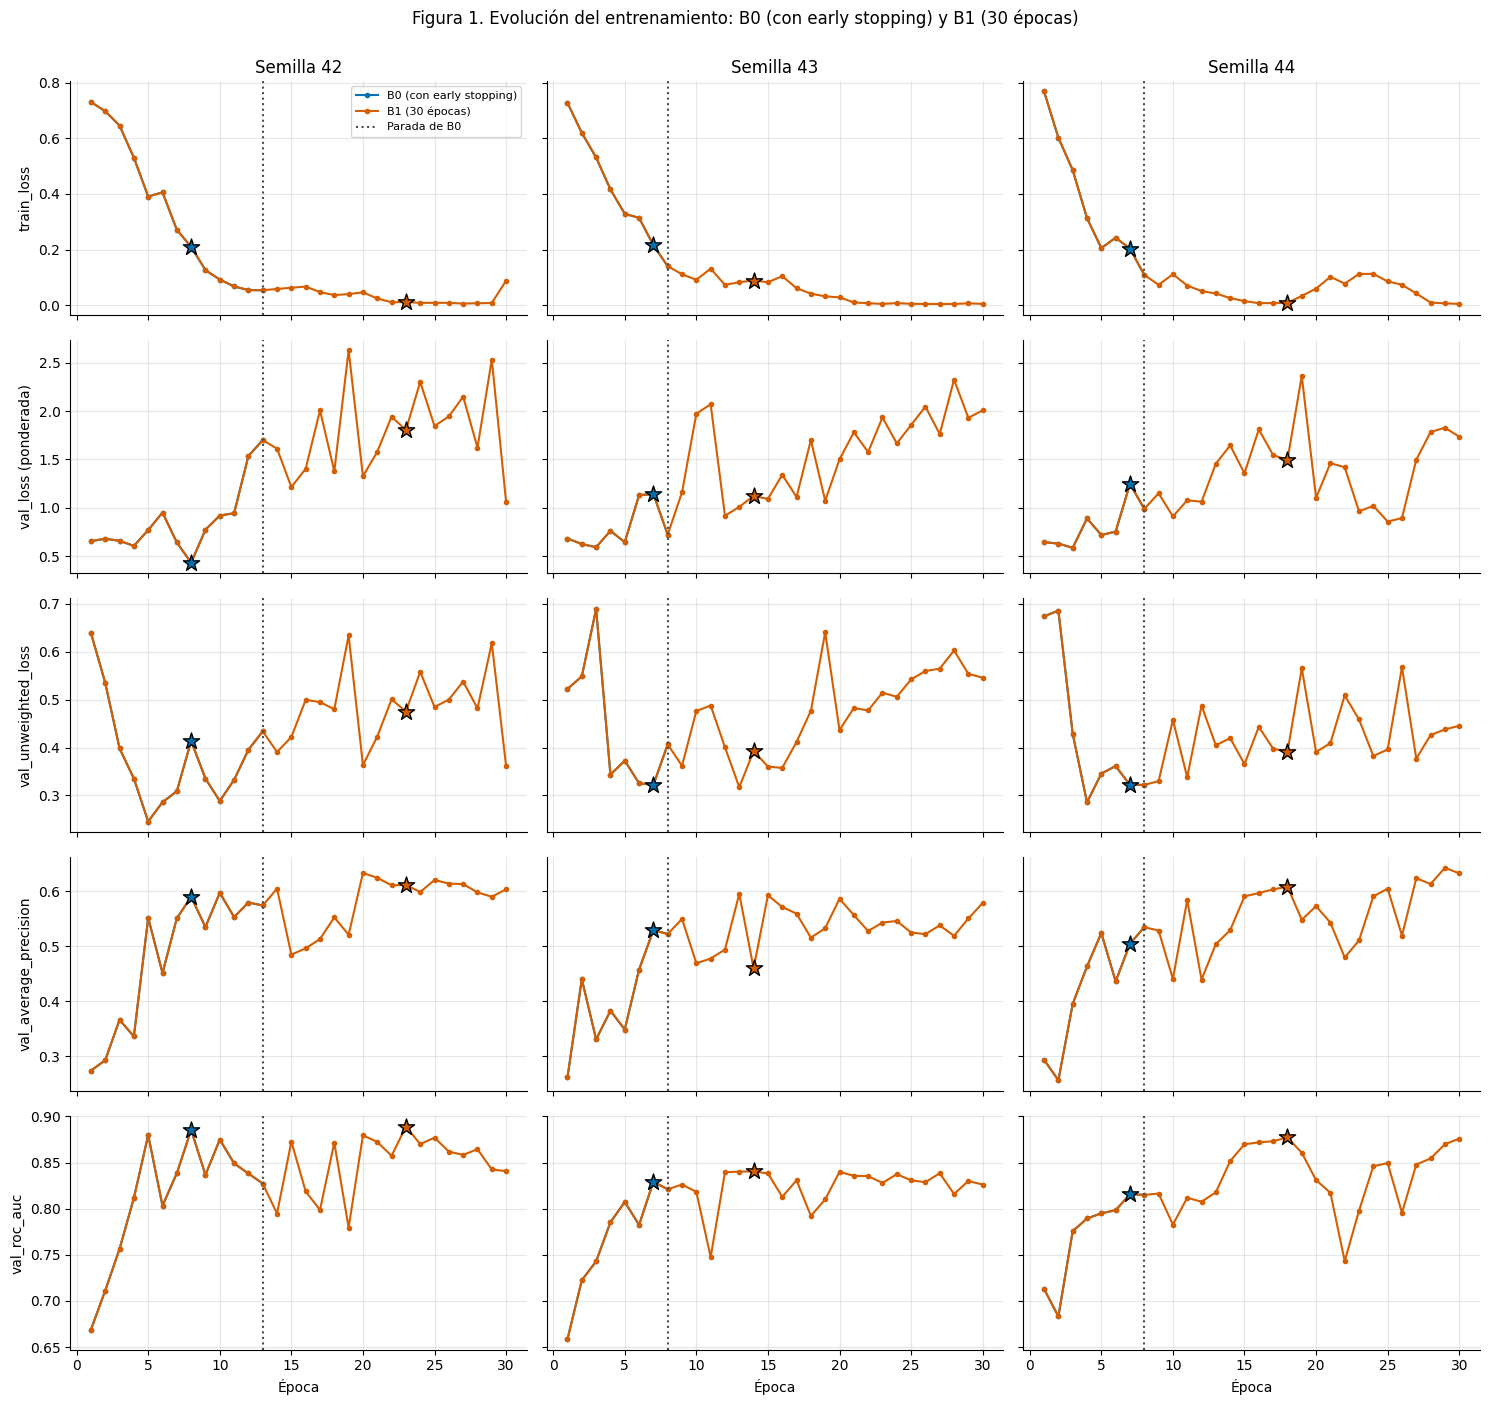

In [7]:
SERIES = [
    ("train_loss", "train_loss"),
    ("val_loss", "val_loss (ponderada)"),
    ("val_unweighted_loss", "val_unweighted_loss"),
    ("val_average_precision", "val_average_precision"),
    ("val_roc_auc", "val_roc_auc"),
]

fig, axes = plt.subplots(len(SERIES), len(SEEDS), figsize=(15, 14), sharex=True, sharey="row")
for col, seed in enumerate(SEEDS):
    for row, (key, label) in enumerate(SERIES):
        ax = axes[row, col]
        for tag, run in (("B0", B0[seed]), ("B1", B1[seed])):
            history, best = run["history"], run["config"]["epoch_best"]
            ax.plot(history.index, history[key], color=COLORS[tag], marker="o", ms=3, label=LABELS[tag] if row == col == 0 else None)
            ax.scatter([best], [history.loc[best, key]], marker="*", s=150, color=COLORS[tag], edgecolors="black", zorder=5)
        ax.axvline(B0[seed]["config"]["epochs_run"], color="0.3", ls=":", label="Parada de B0" if row == col == 0 else None)
        if row == 0:
            ax.set_title(f"Semilla {seed}")
        if col == 0:
            ax.set_ylabel(label)
        if row == len(SERIES) - 1:
            ax.set_xlabel("Época")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Figura 1. Evolución del entrenamiento: B0 (con early stopping) y B1 (30 épocas)", y=1.0)
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / "b0_vs_b1_curvas_entrenamiento.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.2 Average Precision por semilla

AP de cada semilla en B0 y B1, con la diferencia emparejada anotada. Una diferencia nula indica que ambas configuraciones seleccionaron el mismo checkpoint.

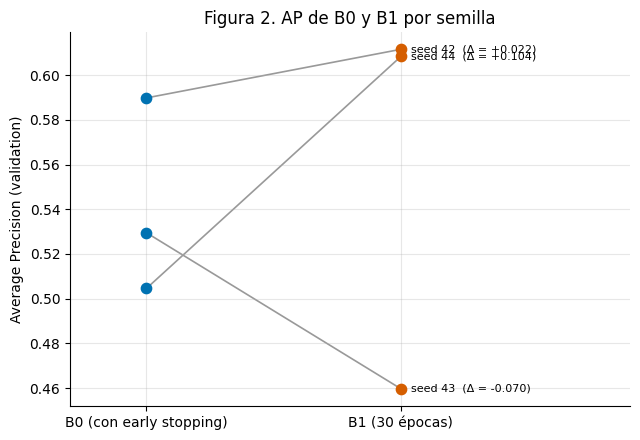

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for _, row in per_seed.iterrows():
    ax.plot([0, 1], [row["average_precision_B0"], row["average_precision_B1"]], color="0.6", lw=1.2, zorder=1)
    ax.scatter([0], [row["average_precision_B0"]], color=COLORS["B0"], s=55, zorder=3)
    ax.scatter([1], [row["average_precision_B1"]], color=COLORS["B1"], s=55, zorder=3)
    ax.annotate(f"seed {int(row['seed'])}  (Δ = {row['delta_average_precision']:+.3f})", (1.04, row["average_precision_B1"]), fontsize=8, va="center")

ax.set_xticks([0, 1])
ax.set_xticklabels([LABELS["B0"], LABELS["B1"]])
ax.set_xlim(-0.3, 1.9)
ax.set_ylabel("Average Precision (validation)")
ax.set_title("Figura 2. AP de B0 y B1 por semilla")
fig.tight_layout()
fig.savefig(ANALYSIS_DIR / "b0_vs_b1_ap_por_semilla.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.3 Épocas posteriores a la parada de B0

Complemento descriptivo, solo dentro del notebook: para cada semilla se compara el mejor valor de B1 en las épocas 1–*k* (ventana de B0) con el de las épocas *k*+1–30. Estos valores de validation están sujetos a ruido, y el máximo de una serie más larga tiende a ser mayor por azar, por lo que no bastan por sí solos para concluir sobre H1.

In [9]:
after_stop = []
for seed in SEEDS:
    k = B0[seed]["config"]["epochs_run"]
    history = B1[seed]["history"]
    inside, after = history.loc[:k], history.loc[k + 1:]
    after_stop.append(
        {
            "seed": seed,
            "k (parada de B0)": k,
            "val_roc_auc máx. 1–k": inside["val_roc_auc"].max(),
            "val_roc_auc máx. k+1–30": after["val_roc_auc"].max(),
            "val_average_precision máx. 1–k": inside["val_average_precision"].max(),
            "val_average_precision máx. k+1–30": after["val_average_precision"].max(),
            "val_loss mín. 1–k": inside["val_loss"].min(),
            "val_loss mín. k+1–30": after["val_loss"].min(),
            "val_loss época 30": history.loc[EPOCHS_MAX, "val_loss"],
            "val_unweighted_loss época 30": history.loc[EPOCHS_MAX, "val_unweighted_loss"],
            "train_loss época 30": history.loc[EPOCHS_MAX, "train_loss"],
        }
    )
pd.DataFrame(after_stop).round(4)

,seed,k (parada de B0),val_roc_auc máx. 1–k,val_roc_auc máx. k+1–30,val_average_precision máx. 1–k,val_average_precision máx. k+1–30,val_loss mín. 1–k,val_loss mín. k+1–30,val_loss época 30,val_unweighted_loss época 30,train_loss época 30
0,42,13,0.8853,0.8889,0.5972,0.6332,0.4321,1.0613,1.0613,0.3611,0.0881
1,43,8,0.8292,0.8404,0.5295,0.5954,0.5930,0.9178,2.0082,0.5459,0.0047
2,44,8,0.8156,0.8772,0.5347,0.6427,0.5860,0.8582,1.7363,0.4453,0.0046


## 6. Limitaciones

- Son tres semillas y 22 imágenes malignas en validation: cada falso negativo equivale a 4.5 puntos de sensibilidad. Las diferencias emparejadas describen lo observado, no constituyen una prueba de efecto.
- Elegir el máximo de `val_roc_auc` entre 30 épocas ofrece más oportunidades de obtener un valor alto en validation que entre 8–13, aun sin mejora real.
- Solo se usa validation; los resultados no estiman el desempeño en datos no vistos.
- El entorno de B0 no quedó registrado y el entrenamiento no fuerza el modo determinista de cuDNN. La reproducción de las primeras *k* épocas se mide (`dif_max_historial_ventana_B0`), no se asume.
- Solo se guardan las probabilidades del checkpoint seleccionado, y no hay identificadores de paciente para verificar independencia entre imágenes.
- Este experimento no explica por qué cambian las métricas; esa interpretación requiere análisis posteriores.

## 7. Interpretación de resultados

El entrenamiento sin early stopping permitió seleccionar checkpoints en épocas posteriores a las registradas en la configuración basal. El AP promedio aumentó de 0.5413 a 0.5599; sin embargo, la mejora no fue consistente entre semillas. La semilla 43 presentó una disminución de AP, mientras que las semillas 42 y 44 mostraron incrementos.

Asimismo, la sensibilidad promedio al umbral 0.5 disminuyó de 0.4545 a 0.4091. Las curvas de entrenamiento mostraron diferencias entre la evolución de las pérdidas y las métricas de discriminación, lo que sugiere que prolongar el entrenamiento no garantiza una mejora general.

En consecuencia, se mantiene B0 como configuración de referencia para los siguientes experimentos de R7. B1 se conserva como una evaluación del efecto del early stopping, sin adoptarse como una optimización definitiva.